<a href="https://colab.research.google.com/github/SanchezGutierrezdiego4354-prog/Detective-de-senales/blob/main/Detective_Senales_Fases_1_2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔎 El Detective de Señales
## Clasificación automática de modulaciones con Deep Learning

**Materia:** Telecomunicaciones  
**Proyecto:** Fases 1, 2 y 3 en un solo cuaderno  
**Alumno/a:** ______________________  
**Escuela:** Tecnológico de Estudios Superiores de Ecatepec (TESE)

Este cuaderno contiene todo el proyecto de principio a fin: genera las señales, entrena una CNN y comprueba qué tan bien las clasifica cuando hay ruido. Se puede ejecutar directamente en **Google Colab** desde el menú **Entorno de ejecución → Ejecutar todas**.

**No necesitas subir archivos adicionales:** la Fase 1 crea los datos; la Fase 2 utiliza esos mismos datos y guarda el modelo; la Fase 3 evalúa el modelo con las 800 señales apartadas para prueba.

> Aviso: el entrenamiento puede tardar varios minutos. La precisión final se calcula al ejecutar el cuaderno; no hay resultados escritos de antemano.

## FASE 1 · Generación y preparación de datos

En esta parte se generan **4,000 señales** (1,000 de cada modulación), con 1,024 puntos por señal y diferentes niveles de ruido AWGN. Se separan 3,200 para entrenamiento/validación y 800 para prueba. La separación de prueba se mantendrá intacta hasta la Fase 3.

### 1.1 Configurar el entorno

Ejecuta este cuaderno en **Google Colab**: abre [colab.research.google.com](https://colab.research.google.com/), selecciona **Archivo → Subir cuaderno** y elige este archivo `.ipynb`. Después ejecuta las celdas de arriba hacia abajo.

Usamos NumPy para operaciones numéricas, Matplotlib para las gráficas, SciPy para analizar espectros y Scikit-learn para separar muestras. Las bibliotecas de redes neuronales (Keras o PyTorch) se emplearán en la fase siguiente.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from sklearn.model_selection import train_test_split

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
print("Entorno listo. NumPy:", np.__version__)

Entorno listo. NumPy: 2.4.6


### 1.2 Definir los parámetros de las señales

| Parámetro | Valor | Significado |
|---|---:|---|
| $f_s$ | 8,000 Hz | Frecuencia de muestreo: puntos que se registran cada segundo |
| $f_c$ | 1,600 Hz | Frecuencia de la portadora |
| $R_s$ | 250 símbolos/s | Cantidad de símbolos transmitidos por segundo |
| $N_s$ | 32 | Símbolos por ejemplo |
| $f_s / R_s$ | 32 | Muestras por símbolo |
| $N$ | 1,024 | Puntos de cada señal: 32 símbolos × 32 muestras |
| $\Delta f$ | 250 Hz | Desplazamiento de frecuencia para FSK |

Cada ejemplo dura $N/f_s=0.128$ segundos. La frecuencia de muestreo cumple el criterio de Nyquist para las portadoras y tonos elegidos. Usamos las cuatro clases: **2-ASK (OOK), 2-FSK, BPSK y 16-QAM**.

In [ ]:
FS = 8000                   # Hz
FC = 1600                   # Hz
RS = 250                    # simbolos por segundo
MUESTRAS_POR_SIMBOLO = FS // RS
NUM_SIMBOLOS = 32
N = NUM_SIMBOLOS * MUESTRAS_POR_SIMBOLO
DELTA_F = 250              # Hz para FSK
MODULACIONES = ["ASK", "FSK", "PSK", "QAM"]
N_POR_CLASE = 1000
NIVELES_SNR = np.array([-5, 0, 5, 10, 15, 20], dtype=np.int16)

assert FS % RS == 0
assert FC + DELTA_F < FS / 2
print(f"{MUESTRAS_POR_SIMBOLO} muestras por simbolo | {N} puntos por señal | {N/FS:.3f} s")

32 muestras por simbolo | 1024 puntos por señal | 0.128 s


### 1.3 Programar los generadores de señales

Las técnicas de modulación cambian distintas propiedades de la portadora:

- **ASK:** cambia la **amplitud** (usamos amplitud 0 y 1: *On-Off Keying*).
- **FSK:** cambia la **frecuencia** (1,350 Hz para el bit 0 y 1,850 Hz para el bit 1).
- **PSK:** cambia la **fase** (usamos BPSK, fases separadas 180°).
- **QAM:** cambia simultáneamente las componentes en **fase** ($I$) y **cuadratura** ($Q$); aquí usamos **16-QAM**, con 16 combinaciones posibles.

Expresiones simplificadas:

$$s_{ASK}(t)=A_k\cos(2\pi f_ct+\phi)$$
$$s_{FSK}(t)=\cos\left(2\pi\int_0^t f(\tau)\,d\tau+\phi\right)$$
$$s_{PSK}(t)=b_k\cos(2\pi f_ct+\phi),\quad b_k\in\{-1,+1\}$$
$$s_{QAM}(t)=I_k\cos(2\pi f_ct+\phi)-Q_k\sin(2\pi f_ct+\phi)$$

En cada muestra se generan símbolos nuevos y una fase inicial aleatoria. Todas las señales limpias se normalizan a una potencia media cercana a 1, para reducir pistas artificiales basadas únicamente en el nivel global de energía.

In [ ]:
def generar_senal_limpia(tipo, generador):
    """Genera una señal real de N muestras, modulada y sin ruido."""
    bits = generador.integers(0, 2, size=NUM_SIMBOLOS)
    fase_inicial = generador.uniform(0, 2 * np.pi)
    t = np.arange(N, dtype=np.float64) / FS
    portadora = 2 * np.pi * FC * t + fase_inicial

    if tipo == "ASK":
        amplitudes = np.repeat(bits, MUESTRAS_POR_SIMBOLO)
        s = amplitudes * np.cos(portadora)

    elif tipo == "FSK":
        frecuencias_por_simbolo = FC + DELTA_F * (2 * bits - 1)
        frecuencia_instantanea = np.repeat(frecuencias_por_simbolo,
                                         MUESTRAS_POR_SIMBOLO)
        # Integracion discreta de frecuencia: fase continua al cambiar de bit.
        fase = fase_inicial + np.concatenate((
            [0.0], 2 * np.pi * np.cumsum(frecuencia_instantanea[:-1]) / FS
        ))
        s = np.cos(fase)

    elif tipo == "PSK":
        simbolos = 2 * bits - 1  # BPSK: valores -1 o +1
        s = np.repeat(simbolos, MUESTRAS_POR_SIMBOLO) * np.cos(portadora)

    elif tipo == "QAM":
        niveles = np.array([-3, -1, 1, 3])
        i_simbolos = generador.choice(niveles, size=NUM_SIMBOLOS)
        q_simbolos = generador.choice(niveles, size=NUM_SIMBOLOS)
        i = np.repeat(i_simbolos, MUESTRAS_POR_SIMBOLO) / np.sqrt(10)
        q = np.repeat(q_simbolos, MUESTRAS_POR_SIMBOLO) / np.sqrt(10)
        s = i * np.cos(portadora) - q * np.sin(portadora)

    else:
        raise ValueError(f"Modulación desconocida: {tipo}")

    potencia = np.mean(s ** 2)
    return (s / np.sqrt(potencia + 1e-12)).astype(np.float32)

# Verificar que las cuatro señales tengan la longitud correcta.
for tipo in MODULACIONES:
    muestra = generar_senal_limpia(tipo, rng)
    print(f"{tipo}: forma={muestra.shape}, potencia={np.mean(muestra**2):.3f}")

ASK: forma=(1024,), potencia=1.000
FSK: forma=(1024,), potencia=1.000
PSK: forma=(1024,), potencia=1.000
QAM: forma=(1024,), potencia=1.000


#### Visualizar las señales limpias

En las gráficas se muestran los primeros cuatro símbolos de cada clase. La forma de onda permite comparar cómo cambia amplitud, frecuencia, fase y combinación amplitud-fase.

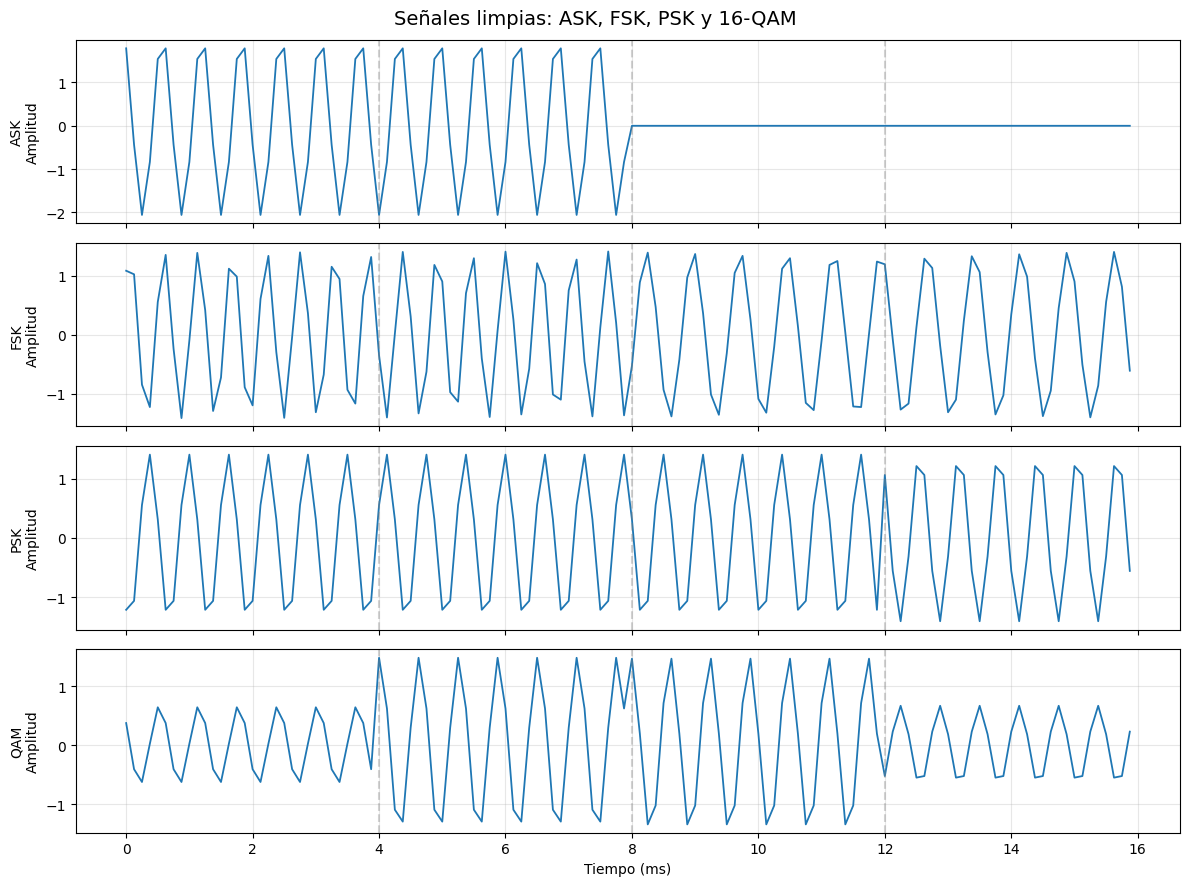

In [ ]:
fig, axs = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
M = 4 * MUESTRAS_POR_SIMBOLO
tiempo_ms = np.arange(M) / FS * 1000

for ax, tipo in zip(axs, MODULACIONES):
    s = generar_senal_limpia(tipo, rng)
    ax.plot(tiempo_ms, s[:M], linewidth=1.3)
    ax.set_ylabel(f"{tipo}\nAmplitud")
    ax.grid(alpha=0.3)
    for x in np.arange(1, 4) * 1000 / RS:
        ax.axvline(x, linestyle="--", alpha=0.35, color="gray")

axs[-1].set_xlabel("Tiempo (ms)")
fig.suptitle("Señales limpias: ASK, FSK, PSK y 16-QAM", fontsize=14)
fig.tight_layout()
fig.savefig("vista_previa_senales.png", dpi=160, bbox_inches="tight")
plt.show()

### 1.5 Añadir ruido gaussiano blanco aditivo (AWGN)

**Ruido gaussiano:** sus valores siguen una distribución normal. **Blanco:** la potencia del ruido se distribuye uniformemente entre frecuencias (idealización). **Aditivo:** se suma directamente a la señal.

La relación señal-ruido se mide en decibelios:

$$SNR_{dB}=10\log_{10}\left(\frac{P_{señal}}{P_{ruido}}\right)$$

Cuando la SNR es **baja** (por ejemplo, –5 dB), resulta difícil distinguir la señal del ruido. Cuando la SNR es **alta** (20 dB), la forma de onda se conserva mucho mejor.

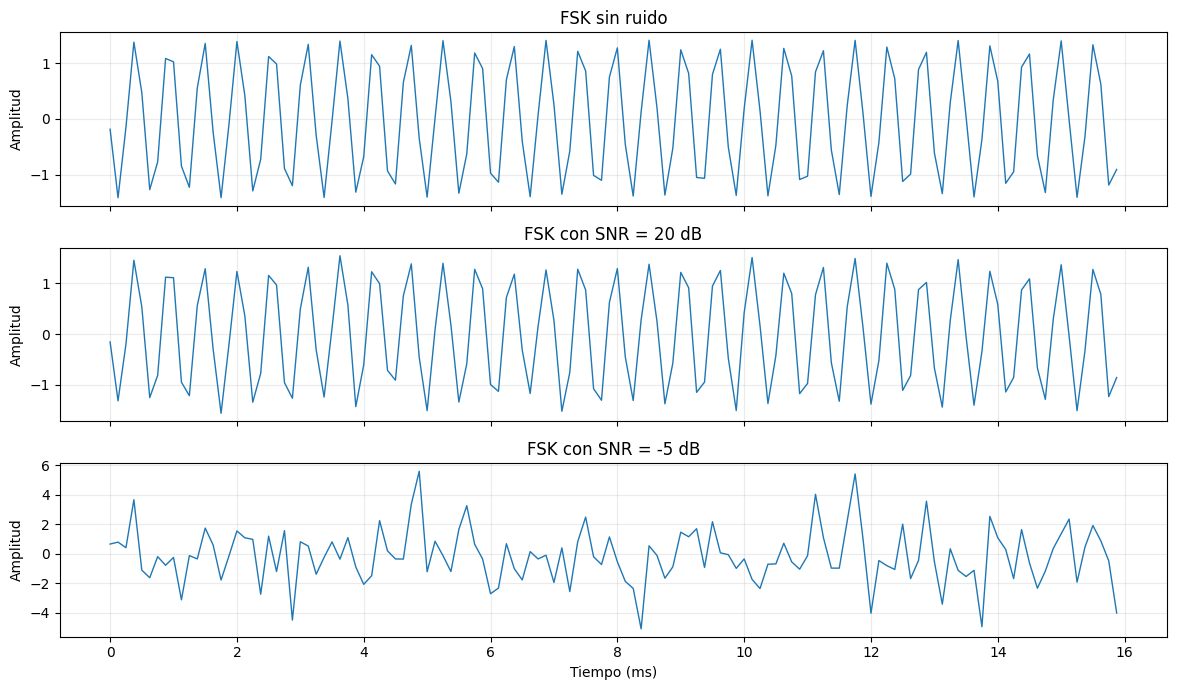

In [ ]:
def agregar_ruido_awgn(senal, snr_db, generador):
    """Suma ruido normal(0,sigma) con la SNR objetivo en dB."""
    potencia_senal = float(np.mean(senal.astype(np.float64) ** 2))
    potencia_ruido = potencia_senal / (10 ** (float(snr_db) / 10))
    desviacion = np.sqrt(potencia_ruido)
    ruido = generador.normal(0, desviacion, size=senal.shape)
    return (senal + ruido).astype(np.float32)

senal_referencia = generar_senal_limpia("FSK", rng)
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, nombre, snr in zip(
    axs,
    ["FSK sin ruido", "FSK con SNR = 20 dB", "FSK con SNR = -5 dB"],
    [None, 20, -5]
):
    s = senal_referencia if snr is None else agregar_ruido_awgn(senal_referencia, snr, rng)
    ax.plot(tiempo_ms, s[:M], linewidth=1.0)
    ax.set_title(nombre)
    ax.set_ylabel("Amplitud")
    ax.grid(alpha=0.25)
axs[-1].set_xlabel("Tiempo (ms)")
fig.tight_layout()
fig.savefig("efecto_ruido_awgn.png", dpi=160, bbox_inches="tight")
plt.show()

### 1.4 Generar el conjunto de datos (dataset)

Se crea **una señal independiente por ejemplo**, se le agrega ruido y se registra su clase. Se usarán **1,000 muestras por modulación**, es decir, **4,000 en total**. Las seis SNR objetivo (–5, 0, 5, 10, 15 y 20 dB) se reparten de manera aproximadamente uniforme dentro de cada clase.

- `X` almacena las ondas: matriz de tamaño **(4000, 1024)**.
- `y` almacena las etiquetas numéricas: **0 = ASK, 1 = FSK, 2 = PSK, 3 = QAM**.
- `snr_db` registra el nivel de ruido asignado a cada onda.

**Importante:** cada muestra es generada de manera independiente; no copiamos la misma onda con varios niveles de ruido. Esto ayuda a evitar que una onda prácticamente idéntica aparezca tanto en entrenamiento como en prueba.

In [ ]:
TOTAL = N_POR_CLASE * len(MODULACIONES)
X = np.empty((TOTAL, N), dtype=np.float32)
y = np.empty(TOTAL, dtype=np.int64)
snr_db = np.empty(TOTAL, dtype=np.int16)

posicion = 0
for clase_id, tipo in enumerate(MODULACIONES):
    # Se reparten los seis niveles y se mezclan en cada clase.
    snr_de_clase = np.resize(NIVELES_SNR, N_POR_CLASE)
    rng.shuffle(snr_de_clase)
    for nivel in snr_de_clase:
        limpia = generar_senal_limpia(tipo, rng)
        X[posicion] = agregar_ruido_awgn(limpia, int(nivel), rng)
        y[posicion] = clase_id
        snr_db[posicion] = nivel
        posicion += 1

print("X (ondas):", X.shape)
print("y (clases):", y.shape)
print("snr_db:", snr_db.shape)
print("Tipo de datos:", X.dtype)
print("Muestras por clase:")
for idx, tipo in enumerate(MODULACIONES):
    print(f"  {tipo}: {np.sum(y == idx)}")
assert posicion == 4000
assert X.shape == (4000, 1024)
assert np.isfinite(X).all()

X (ondas): (4000, 1024)
y (clases): (4000,)
snr_db: (4000,)
Tipo de datos: float32
Muestras por clase:
  ASK: 1000
  FSK: 1000
  PSK: 1000
  QAM: 1000


### 1.6 Separar entrenamiento (80 %) y prueba (20 %)

En cada tipo de modulación apartamos 200 ejemplos de prueba y 800 de entrenamiento. Se **estratifica por SNR dentro de cada clase** para conservar una mezcla parecida de señales fáciles y difíciles en ambos conjuntos.

La prueba se guarda aparte: **no debe usarse para ajustar el modelo**. Cuando llegue la fase de entrenamiento, se puede obtener una porción de validación desde el conjunto de entrenamiento.

In [ ]:
indices_entrenamiento = []
indices_prueba = []

for clase_id in range(len(MODULACIONES)):
    indices_clase = np.flatnonzero(y == clase_id)
    ent, pru = train_test_split(
        indices_clase,
        test_size=0.20,
        random_state=SEMILLA + clase_id,
        stratify=snr_db[indices_clase]
    )
    indices_entrenamiento.extend(ent)
    indices_prueba.extend(pru)

# Mezclar el orden de las clases después de separar.
mezclador = np.random.default_rng(SEMILLA + 100)
indices_entrenamiento = mezclador.permutation(indices_entrenamiento)
indices_prueba = mezclador.permutation(indices_prueba)

X_train = X[indices_entrenamiento]
y_train = y[indices_entrenamiento]
snr_train = snr_db[indices_entrenamiento]
X_test = X[indices_prueba]
y_test = y[indices_prueba]
snr_test = snr_db[indices_prueba]

assert len(np.intersect1d(indices_entrenamiento, indices_prueba)) == 0
assert len(X_train) == 3200 and len(X_test) == 800

print("ENTRENAMIENTO:", X_train.shape, "etiquetas", y_train.shape)
print("PRUEBA:", X_test.shape, "etiquetas", y_test.shape)
print("\nCantidad por modulación:")
for clase_id, tipo in enumerate(MODULACIONES):
    print(f"{tipo:3s}: entrenamiento={np.sum(y_train == clase_id)}, "
          f"prueba={np.sum(y_test == clase_id)}")

ENTRENAMIENTO: (3200, 1024) etiquetas (3200,)
PRUEBA: (800, 1024) etiquetas (800,)

Cantidad por modulación:
ASK: entrenamiento=800, prueba=200
FSK: entrenamiento=800, prueba=200
PSK: entrenamiento=800, prueba=200
QAM: entrenamiento=800, prueba=200


### Revisar distribución de los datos

La tabla permite demostrar que no hay clases desbalanceadas: por cada tipo de modulación hay 1,000 señales y una variedad de niveles de ruido.

In [ ]:
resumen = pd.crosstab(
    index=pd.Series(np.array(MODULACIONES)[y], name="Modulación"),
    columns=pd.Series(snr_db, name="SNR (dB)")
)
resumen["TOTAL"] = resumen.sum(axis=1)
print(resumen.to_string())

SNR (dB)     -5    0    5   10   15   20  TOTAL
Modulación                                     
ASK         167  167  167  167  166  166   1000
FSK         167  167  167  167  166  166   1000
PSK         167  167  167  167  166  166   1000
QAM         167  167  167  167  166  166   1000


### Análisis adicional: espectro de frecuencias

El espectro sirve para observar cómo se distribuye la potencia de una señal por frecuencia; ayuda a interpretar lo visto en Telecomunicaciones. El espectro de una sola señal no siempre permite reconocer inequívocamente su modulación, especialmente con ruido.

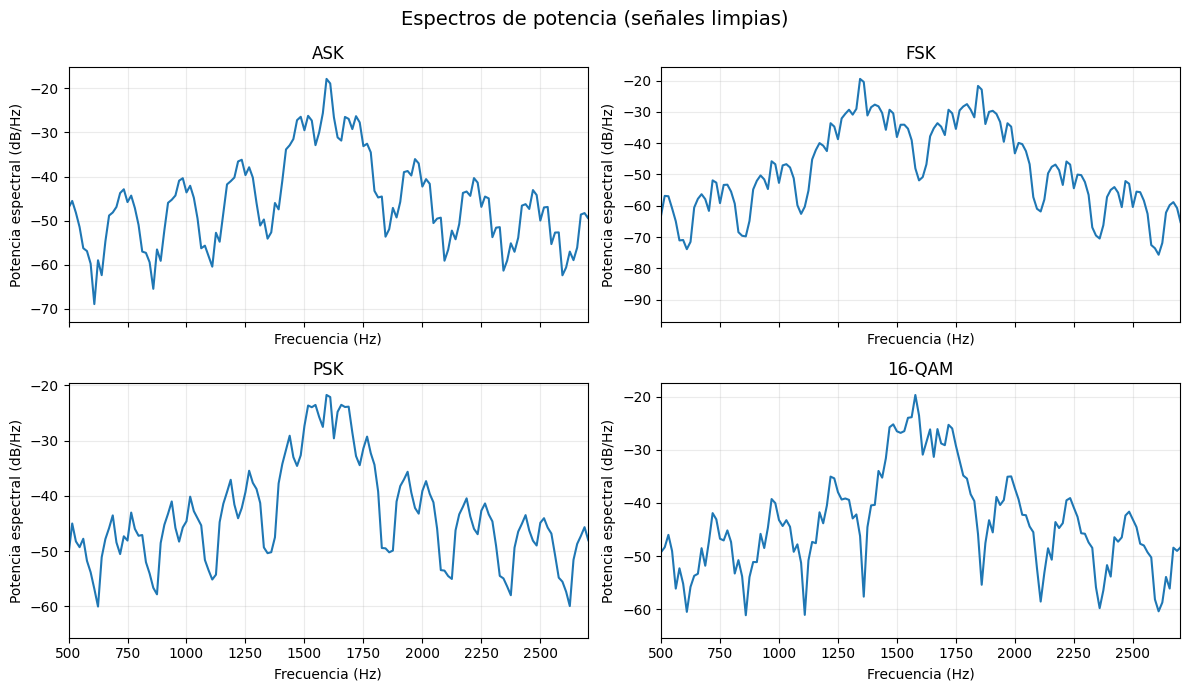

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, tipo in zip(axs.flat, MODULACIONES):
    s = generar_senal_limpia(tipo, rng)
    freq, potencia = welch(s, fs=FS, nperseg=512)
    ax.plot(freq, 10 * np.log10(potencia + 1e-15))
    ax.set_title(tipo if tipo != "QAM" else "16-QAM")
    ax.set_xlim(500, 2700)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Potencia espectral (dB/Hz)")
    ax.grid(alpha=0.25)
fig.suptitle("Espectros de potencia (señales limpias)", fontsize=14)
fig.tight_layout()
fig.savefig("espectros_modulaciones.png", dpi=160, bbox_inches="tight")
plt.show()

### Guardar los archivos para las siguientes fases

Generamos:

1. **`datos_senales.npz`**: ondas y etiquetas para entrenamiento y prueba, junto con sus parámetros.
2. **`metadatos_senales.csv`**: nombre de clase, SNR y conjunto de cada muestra.
3. **Tres gráficas `.png`**: comparación de modulaciones, efecto AWGN y espectros.

**Para obtenerlos de Google Colab:** abre el panel izquierdo **Archivos**, ubica los nombres y usa el menú de tres puntos → **Descargar**. También puedes descomentar las dos líneas finales del código para descargar directamente el `.npz`.

In [ ]:
np.savez_compressed(
    "datos_senales.npz",
    X_train=X_train, y_train=y_train, snr_train=snr_train,
    X_test=X_test, y_test=y_test, snr_test=snr_test,
    modulaciones=np.array(MODULACIONES),
    clases=np.array(MODULACIONES),
    fs=FS, fc=FC, rs=RS,
    num_simbolos=NUM_SIMBOLOS, muestras_por_simbolo=MUESTRAS_POR_SIMBOLO,
    niveles_snr=NIVELES_SNR, semilla=SEMILLA
)

metadata_train = pd.DataFrame({
    "id": [f"train_{i:04d}" for i in range(len(X_train))],
    "conjunto": "entrenamiento",
    "etiqueta_numerica": y_train,
    "modulacion": np.array(MODULACIONES)[y_train],
    "snr_db": snr_train
})
metadata_test = pd.DataFrame({
    "id": [f"test_{i:04d}" for i in range(len(X_test))],
    "conjunto": "prueba",
    "etiqueta_numerica": y_test,
    "modulacion": np.array(MODULACIONES)[y_test],
    "snr_db": snr_test
})
pd.concat([metadata_train, metadata_test], ignore_index=True).to_csv(
    "metadatos_senales.csv", index=False, encoding="utf-8-sig"
)

with np.load("datos_senales.npz") as archivo:
    print("Archivo guardado y verificado:")
    print("Entrenamiento:", archivo["X_train"].shape)
    print("Prueba:", archivo["X_test"].shape)
    print("Clases:", archivo["clases"].tolist())
print("Metadatos guardados: metadatos_senales.csv")

# Descarga directa opcional SOLO en Google Colab:
# from google.colab import files
# files.download("datos_senales.npz")

Archivo guardado y verificado:
Entrenamiento: (3200, 1024)
Prueba: (800, 1024)
Clases: ['ASK', 'FSK', 'PSK', 'QAM']
Metadatos guardados: metadatos_senales.csv


---
## FASE 2 · Diseño y entrenamiento de la CNN

La red neuronal aprenderá a clasificar las señales. De las **3,200 muestras de entrenamiento**, se usarán 2,560 para ajustar la CNN y 640 para validarla. Las **800 de prueba siguen reservadas** para la Fase 3.

Para enlazar los tres pasos, el conjunto de datos se guardó en `datos_senales.npz` en la Fase 1. Aquí se **carga ese archivo sin generar señales nuevas**.

## 2.1 Investigación: ¿por qué usar una CNN?

Una red neuronal convolucional (CNN) usa filtros que se van recorriendo sobre los datos para encontrar patrones. En una señal, estos patrones pueden ser cambios de amplitud, cambios de frecuencia o transiciones de fase. Los filtros aprenden durante el entrenamiento cuáles son útiles para distinguir las modulaciones.

Hay dos formas de utilizar una CNN en este proyecto:

- **CNN 1D:** recibe directamente las muestras de la forma de onda, en orden temporal. No hace falta convertir la señal en una imagen.
- **CNN 2D:** primero se convierte la señal en un espectrograma, que muestra cómo cambia el contenido de frecuencia con el tiempo. Después se analiza como una imagen.

Voy a utilizar una CNN 1D porque cada señal tiene 1024 muestras y ya está guardada como un vector. Así no tengo que transformar las señales antes de entrenar.

Fuentes consultadas: [Conv1D de Keras](https://keras.io/api/layers/convolution_layers/convolution1d/), [Entrenamiento con Keras](https://keras.io/guides/training_with_built_in_methods/).

### Cargar las bibliotecas y recuperar los datos

La red se hará con TensorFlow y Keras. NumPy se usa para manejar las señales, Matplotlib para las gráficas y Scikit-learn para dividir los datos.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(15)
print("Bibliotecas para preparar los datos: listas")

Bibliotecas para preparar los datos: listas


In [ ]:
import os

if not os.path.isfile("datos_senales.npz"):
    raise FileNotFoundError(
        "No existe datos_senales.npz. Ejecuta primero todas las celdas de la Fase 1."
    )
print("Archivo de la Fase 1 encontrado: datos_senales.npz")
print("Se utilizarán las mismas señales en las fases 2 y 3.")

Archivo de la Fase 1 encontrado: datos_senales.npz
Se utilizarán las mismas señales en las fases 2 y 3.


### Preparar la entrada de la red

Hay 3200 señales para entrenamiento y 800 reservadas para prueba. De las 3200 primeras, separo 640 para validación. Con esto puedo observar qué tan bien aprende la red con datos que no utiliza para ajustar los pesos.

| Conjunto | Señales |
|---|---:|
| Entrenamiento efectivo | 2560 |
| Validación | 640 |
| Prueba (reservada para la siguiente fase) | 800 |

Cada señal se convierte a una matriz de 1024 filas y 1 canal para que pueda entrar a Conv1D. Las etiquetas se convierten a cuatro posiciones (one-hot), por ejemplo ASK = [1, 0, 0, 0].

In [ ]:
with np.load("datos_senales.npz", allow_pickle=False) as datos:
    X_train = datos["X_train"].astype(np.float32)
    y_train = datos["y_train"].astype(int)
    snr_train = datos["snr_train"]
    X_test = datos["X_test"].astype(np.float32)
    y_test = datos["y_test"].astype(int)
    snr_test = datos["snr_test"]
    modulaciones = datos["modulaciones"].tolist()

assert modulaciones == ["ASK", "FSK", "PSK", "QAM"]
assert X_train.shape == (3200, 1024) and X_test.shape == (800, 1024)
assert len(y_train) == 3200 and len(y_test) == 800

# Mantengo la proporción de cada modulación y nivel de ruido
grupos = [f"{clase}_{snr}" for clase, snr in zip(y_train, snr_train)]
ind_ent, ind_val = train_test_split(
    np.arange(len(y_train)), test_size=0.20,
    random_state=15, stratify=grupos
)

X_ent = X_train[ind_ent, :, np.newaxis]
X_val = X_train[ind_val, :, np.newaxis]
y_ent = np.eye(4, dtype=np.float32)[y_train[ind_ent]]
y_val = np.eye(4, dtype=np.float32)[y_train[ind_val]]

print("Entrenamiento:", X_ent.shape)
print("Validación:", X_val.shape)
print("Prueba reservada:", X_test.shape)

Entrenamiento: (2560, 1024, 1)
Validación: (640, 1024, 1)
Prueba reservada: (800, 1024)


## 2.2 Diseño del modelo

La primera capa recibe los 1024 datos de amplitud. Las dos capas Conv1D buscan patrones en diferentes tamaños de ventana. ReLU ayuda a aprender relaciones no lineales. MaxPooling reduce la cantidad de datos que pasan a las siguientes capas.

Al final, Flatten convierte los resultados en un solo vector y la salida Softmax genera cuatro probabilidades: una por cada tipo de modulación.

| Capa | Función |
|---|---|
| Entrada | Recibe 1024 muestras y 1 canal |
| Conv1D (32 filtros) + ReLU | Busca patrones en la forma de onda |
| MaxPooling1D | Reduce el tamaño a 256 muestras |
| Conv1D (64 filtros) + ReLU | Aprende patrones más complejos |
| MaxPooling1D | Reduce el tamaño a 32 posiciones |
| Flatten | Convierte las características en un vector |
| Dense (64) + ReLU | Combina las características |
| Dropout | Ayuda a reducir el sobreajuste |
| Dense (4) + Softmax | Calcula la probabilidad de cada modulación |

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(15)
print("TensorFlow:", tf.__version__)
print("GPU disponible:", bool(tf.config.list_physical_devices("GPU")))

modelo = keras.Sequential([
    keras.Input(shape=(1024, 1)),
    layers.Conv1D(32, kernel_size=17, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=4),
    layers.Conv1D(64, kernel_size=9, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=8),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(4, activation="softmax")
])

modelo.summary()

TensorFlow: 2.21.0
GPU disponible: False


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 1024, 32)       │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 256, 64)        │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 32, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 150,468 (587.77 KB)

 Trainable params: 150,468 (587.77 KB)

 Non-trainable params: 0 (0.00 B)

## 2.3 Compilar el modelo

- **Adam:** ajusta los pesos de la red durante el aprendizaje.
- **Categorical crossentropy:** mide el error al comparar las cuatro probabilidades con la clase real.
- **Accuracy:** indica qué proporción de las señales se clasificaron correctamente.

In [ ]:
modelo.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Modelo compilado correctamente")

Modelo compilado correctamente


## 2.4 Entrenar el modelo

Voy a usar hasta 25 épocas (una época es una vuelta completa por los datos de entrenamiento) y lotes de 32 señales.

En esta celda puedo ver cómo avanzan las épocas, el error (loss) y la precisión (accuracy). También se muestran los valores de validación. Los resultados no tienen que mejorar en absolutamente todas las épocas.

El checkpoint guarda automáticamente el modelo cuando mejora la pérdida de validación. Si después de varias épocas no mejora, el entrenamiento se detiene para evitar que continúe sin beneficio.

In [ ]:
epocas = 25
lote = 32

guardar_mejor = keras.callbacks.ModelCheckpoint(
    "modelo_senales.keras", monitor="val_loss",
    save_best_only=True, verbose=0
)
detener = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True
)

historial = modelo.fit(
    X_ent, y_ent,
    validation_data=(X_val, y_val),
    epochs=epocas,
    batch_size=lote,
    callbacks=[guardar_mejor, detener],
    verbose=1
)

Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.6145 - loss: 0.8294 - val_accuracy: 0.8578 - val_loss: 0.3789
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.9035 - loss: 0.2818 - val_accuracy: 0.8984 - val_loss: 0.2772
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9320 - loss: 0.1953 - val_accuracy: 0.9234 - val_loss: 0.1740
Epoch 4/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.9520 - loss: 0.1323 - val_accuracy: 0.9469 - val_loss: 0.1224
Epoch 5/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.9605 - loss: 0.1053 - val_accuracy: 0.9516 - val_loss: 0.1100
Epoch 6/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.9746 - loss: 0.0727 - val_accuracy: 0.9609 - val_loss: 0.0934
Epoch 7/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.9754 - loss: 0.0669 - val_accuracy: 0.9641 - val_loss: 0.0860
Epoch 8/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.9719 - loss: 0.0688 - val_accuracy: 0.9266 - 

### Gráficas de precisión y pérdida

La primera gráfica muestra la precisión durante las épocas y la segunda muestra el error. Comparo entrenamiento y validación para detectar si el modelo empieza a memorizar los datos.

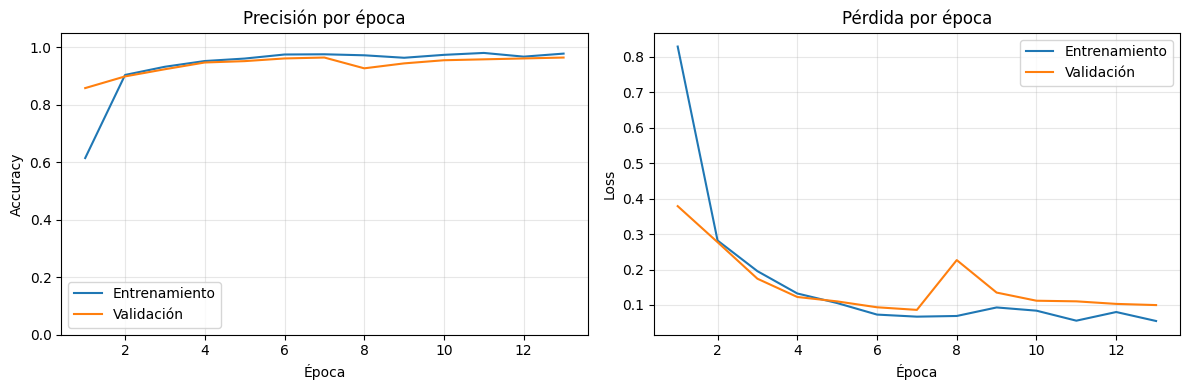

Mejor época según la pérdida de validación: 7
Precisión de validación en esa época: 96.41%


In [ ]:
registro = pd.DataFrame(historial.history)
registro.index = np.arange(1, len(registro) + 1)
registro.index.name = "epoca"

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(registro.index, registro["accuracy"], label="Entrenamiento")
axs[0].plot(registro.index, registro["val_accuracy"], label="Validación")
axs[0].set_title("Precisión por época")
axs[0].set_xlabel("Época")
axs[0].set_ylabel("Accuracy")
axs[0].set_ylim(0, 1.05)
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].plot(registro.index, registro["loss"], label="Entrenamiento")
axs[1].plot(registro.index, registro["val_loss"], label="Validación")
axs[1].set_title("Pérdida por época")
axs[1].set_xlabel("Época")
axs[1].set_ylabel("Loss")
axs[1].legend()
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("graficas_entrenamiento.png", dpi=150)
plt.show()

mejor_epoca = registro["val_loss"].idxmin()
print("Mejor época según la pérdida de validación:", mejor_epoca)
print(f"Precisión de validación en esa época: {registro.loc[mejor_epoca, 'val_accuracy']:.2%}")

## 2.5 Guardar el modelo entrenado

El archivo .keras guarda la estructura de la red y sus pesos. Cargo el mejor modelo según la pérdida de validación y compruebo que pueda volver a abrirse. También guardo el historial de entrenamiento.

La evaluación final se hará en la siguiente fase con las 800 señales de prueba que no se usaron aquí.

In [ ]:
modelo = keras.models.load_model("modelo_senales.keras")
# Exporto el mejor modelo para la siguiente fase
modelo.save("modelo_senales.keras")
registro.to_csv("historial_entrenamiento.csv")

modelo_guardado = keras.models.load_model("modelo_senales.keras")
assert modelo_guardado.input_shape == (None, 1024, 1)
assert modelo_guardado.output_shape == (None, 4)

print("Modelo guardado: modelo_senales.keras")
print("Historial: historial_entrenamiento.csv")
print("Gráficas: graficas_entrenamiento.png")

Modelo guardado: modelo_senales.keras
Historial: historial_entrenamiento.csv
Gráficas: graficas_entrenamiento.png


### Ejemplo: ver una predicción del modelo

Para comprobar cómo se utiliza el modelo guardado, voy a mostrar una señal de validación y las cuatro probabilidades que devuelve para esa señal. Esto es solo una demostración; todavía no es la evaluación final.

Modulación real: FSK
Predicción: FSK


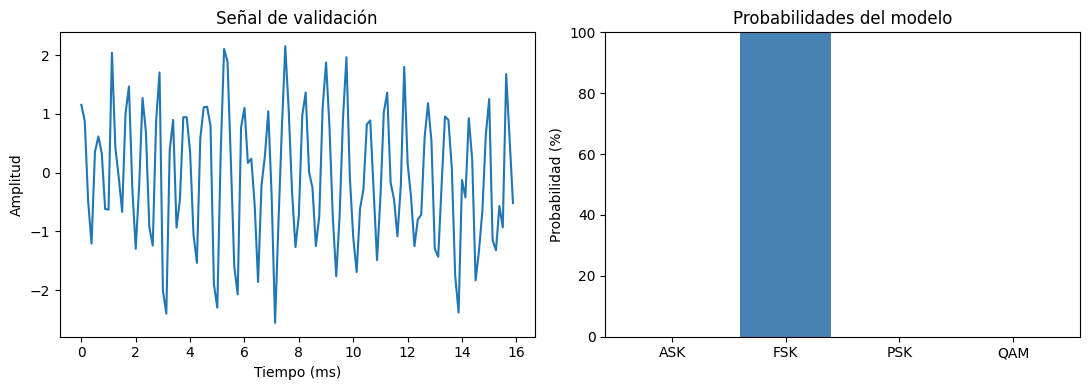

In [ ]:
ejemplo = 0
probabilidades = modelo_guardado.predict(X_val[ejemplo:ejemplo+1], verbose=0)[0]
real = modulaciones[np.argmax(y_val[ejemplo])]
prediccion = modulaciones[np.argmax(probabilidades)]

print("Modulación real:", real)
print("Predicción:", prediccion)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(np.arange(128) / 8000 * 1000, X_val[ejemplo, :128, 0])
axs[0].set_title("Señal de validación")
axs[0].set_xlabel("Tiempo (ms)")
axs[0].set_ylabel("Amplitud")

axs[1].bar(modulaciones, probabilidades * 100, color="steelblue")
axs[1].set_title("Probabilidades del modelo")
axs[1].set_ylabel("Probabilidad (%)")
axs[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()

### Descargar y conservar los resultados

El modelo y el dataset **ya están disponibles para la Fase 3**, que se ejecuta a continuación en este mismo cuaderno. No necesitas descargarlos ni subirlos de nuevo.

Si deseas conservar los resultados en tu computadora, abre la carpeta de archivos de Colab y descarga `modelo_senales.keras`, `datos_senales.npz`, `historial_entrenamiento.csv` y `graficas_entrenamiento.png`. Los archivos de Colab son temporales: conviene descargarlos antes de desconectar la sesión.

## Conclusión

La CNN permite pasar de una forma de onda a una predicción de su modulación. Para concluir esta fase, después de ejecutar el cuaderno anota la mejor época, la precisión de validación y si observaste diferencia entre las gráficas de entrenamiento y validación. La precisión final se medirá posteriormente con los datos de prueba.

Referencia para guardar y recuperar el modelo: [Keras: guardado y carga](https://keras.io/api/models/model_saving_apis/model_saving_and_loading/).

---
## FASE 3 · Evaluación y robustez frente al ruido

En esta parte **no se vuelve a entrenar** el modelo: se carga el mejor `modelo_senales.keras` de la Fase 2 y se evalúan las 800 señales reservadas. Se obtienen matriz de confusión, precisión por nivel de SNR, gráficas de rendimiento y análisis de errores.

In [ ]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from tensorflow import keras

print("Bibliotecas cargadas correctamente")

Bibliotecas cargadas correctamente


### 3.0 Cargar el modelo y las señales de prueba

In [ ]:
archivos_necesarios = ["modelo_senales.keras", "datos_senales.npz"]
faltan = [nombre for nombre in archivos_necesarios if not os.path.isfile(nombre)]
if faltan:
    raise FileNotFoundError(
        "No se encontraron " + ", ".join(faltan) +
        ". Ejecuta en orden las fases 1 y 2 de este cuaderno."
    )
print("Modelo entrenado y señales de prueba disponibles.")

Modelo entrenado y señales de prueba disponibles.


In [ ]:
with np.load("datos_senales.npz", allow_pickle=False) as datos:
    campos = {"X_test", "y_test", "snr_test", "modulaciones"}
    if not campos.issubset(datos.files):
        raise ValueError(
            "Este archivo no tiene el formato de la Fase 2. "
            "Se necesita datos_senales.npz de ese cuaderno."
        )
    X_test = datos["X_test"].astype(np.float32)
    y_test = datos["y_test"].astype(int)
    snr_test = datos["snr_test"].astype(int)
    modulaciones = [str(x) for x in datos["modulaciones"].tolist()]

if modulaciones != ["ASK", "FSK", "PSK", "QAM"]:
    raise ValueError("Las clases no coinciden con las de la Fase 2")
if X_test.shape != (800, 1024) or y_test.shape != (800,) or snr_test.shape != (800,):
    raise ValueError("Las dimensiones de prueba no son las esperadas (800 señales de 1024 muestras)")
if not np.isfinite(X_test).all() or not np.isin(y_test, range(4)).all():
    raise ValueError("El conjunto de prueba tiene valores incorrectos")

modelo = keras.models.load_model("modelo_senales.keras", compile=False)
if tuple(modelo.input_shape[1:]) != (1024, 1) or tuple(modelo.output_shape[1:]) != (4,):
    raise ValueError("El modelo no corresponde a la arquitectura de la Fase 2")

X_entrada = X_test[:, :, np.newaxis]
print("Modelo cargado:", modelo.name)
print("Señales de prueba:", X_entrada.shape)
print("Distribución por clase:", {m: int(np.sum(y_test == i)) for i, m in enumerate(modulaciones)})
print("SNR disponibles (dB):", sorted(np.unique(snr_test).tolist()))
print("No se ha entrenado el modelo en esta fase.")

Modelo cargado: sequential
Señales de prueba: (800, 1024, 1)
Distribución por clase: {'ASK': 200, 'FSK': 200, 'PSK': 200, 'QAM': 200}
SNR disponibles (dB): [-5, 0, 5, 10, 15, 20]
No se ha entrenado el modelo en esta fase.


## 3.1 Matriz de confusión

La matriz de confusión compara las **etiquetas reales** con las **predicciones** de la red. Los valores de la diagonal son aciertos; los que están fuera de la diagonal son confusiones.

También voy a revisar por separado si la red confunde ASK con PSK. La matriz de la derecha muestra porcentajes por clase, para comparar incluso si cambia la cantidad de señales.

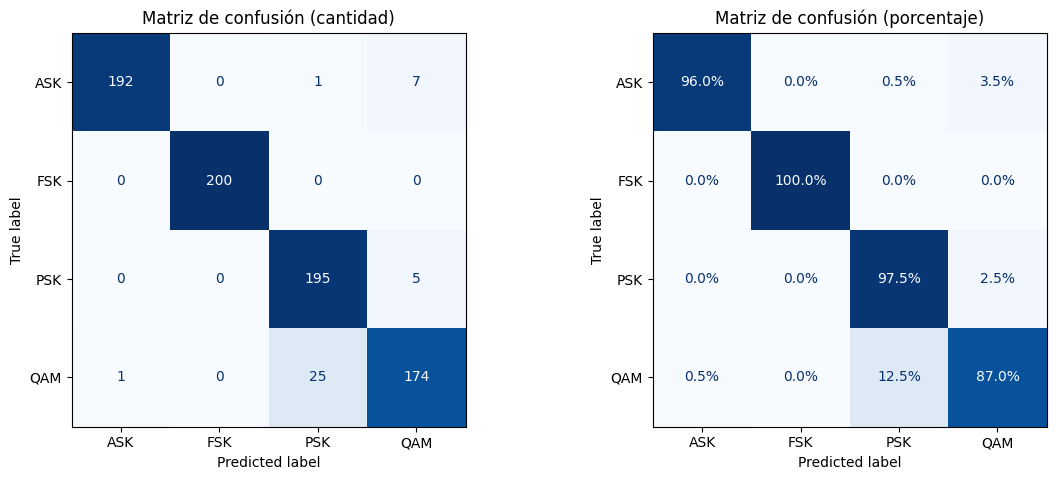

Precisión total en prueba: 95.12% (761/800)
Filas = clase real; columnas = clase predicha


In [ ]:
probabilidades = modelo.predict(X_entrada, batch_size=64, verbose=0)
if probabilidades.shape != (len(y_test), 4):
    raise ValueError("La red debe dar cuatro probabilidades por señal")
y_pred = np.argmax(probabilidades, axis=1)
exactitud = accuracy_score(y_test, y_pred)

matriz = confusion_matrix(y_test, y_pred, labels=np.arange(4))
matriz_porcentaje = matriz / matriz.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
ConfusionMatrixDisplay(matriz, display_labels=modulaciones).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d"
)
axes[0].set_title("Matriz de confusión (cantidad)")
ConfusionMatrixDisplay(matriz_porcentaje, display_labels=modulaciones).plot(
    ax=axes[1], cmap="Blues", colorbar=False, values_format=".1%"
)
axes[1].set_title("Matriz de confusión (porcentaje)")
fig.tight_layout()
fig.savefig("matriz_confusion_fase3.png", dpi=160, bbox_inches="tight")
plt.show()

pd.DataFrame(matriz, index=modulaciones, columns=modulaciones).to_csv(
    "matriz_confusion_fase3.csv", index_label="Clase real"
)
print(f"Precisión total en prueba: {exactitud * 100:.2f}% ({int(np.trace(matriz))}/800)")
print("Filas = clase real; columnas = clase predicha")

In [ ]:
ask_como_psk = int(matriz[0, 2])
psk_como_ask = int(matriz[2, 0])
print(f"ASK confundidas con PSK: {ask_como_psk}")
print(f"PSK confundidas con ASK: {psk_como_ask}")

if ask_como_psk + psk_como_ask > 0:
    print("Sí hubo confusiones ASK/PSK en este conjunto de prueba.")
    print("Hipótesis: el ruido dificulta distinguir cambios de amplitud y de fase en algunas formas de onda.")
else:
    print("No hubo confusiones ASK/PSK en estas 800 señales de prueba.")
    print("Esto no garantiza que nunca ocurran con otras señales o niveles de ruido.")

ASK confundidas con PSK: 1
PSK confundidas con ASK: 0
Sí hubo confusiones ASK/PSK en este conjunto de prueba.
Hipótesis: el ruido dificulta distinguir cambios de amplitud y de fase en algunas formas de onda.


## 3.2 Prueba de estrés con ruido

Las 800 señales de prueba ya tienen diferentes niveles de ruido. **SNR baja significa más ruido** en relación con la señal; **SNR alta significa una señal más clara**. Evaluaré cada nivel por separado, sin modificar el modelo.

Usaré las mismas SNR de la Fase 1: **−5, 0, 5, 10, 15 y 20 dB**. Además compararé tres grupos: bajo (−5 y 0), medio (5 y 10) y alto (15 y 20).

In [ ]:
filas = []
for snr in sorted(np.unique(snr_test)):
    indices = snr_test == snr
    n = int(indices.sum())
    aciertos = int(np.sum(y_pred[indices] == y_test[indices]))
    filas.append({"SNR (dB)": int(snr), "Señales": n,
                  "Aciertos": aciertos, "Precisión (%)": round(100 * aciertos / n, 2)})

resultados_snr = pd.DataFrame(filas)
print("RESULTADOS POR NIVEL DE RUIDO")
print(resultados_snr.to_string(index=False))
resultados_snr.to_csv("precision_por_snr.csv", index=False)

print("\nRESULTADOS POR GRUPO")
grupos_ruido = {
    "Bajo (−5 y 0 dB)": [-5, 0],
    "Medio (5 y 10 dB)": [5, 10],
    "Alto (15 y 20 dB)": [15, 20],
}
for grupo, niveles in grupos_ruido.items():
    indices = np.isin(snr_test, niveles)
    cantidad = int(indices.sum())
    if cantidad:
        acc = 100 * np.mean(y_pred[indices] == y_test[indices])
        print(f"{grupo}: {acc:.2f}% de aciertos ({cantidad} señales)")

RESULTADOS POR NIVEL DE RUIDO
 SNR (dB)  Señales  Aciertos  Precisión (%)
       -5      133        97          72.93
        0      133       130          97.74
        5      135       135         100.00
       10      135       135         100.00
       15      132       132         100.00
       20      132       132         100.00

RESULTADOS POR GRUPO
Bajo (−5 y 0 dB): 85.34% de aciertos (266 señales)
Medio (5 y 10 dB): 100.00% de aciertos (270 señales)
Alto (15 y 20 dB): 100.00% de aciertos (264 señales)


## 3.3 Gráfica de rendimiento

El eje horizontal será la relación señal-ruido (**SNR, dB**) y el vertical la **precisión**. Con esto se ve si el clasificador resiste el ruido o si empieza a equivocarse cuando la señal se degrada.

Como referencia, elegir una modulación al azar entre cuatro clases equilibradas daría aproximadamente **25 % de aciertos**. Es solo un punto de comparación, no un resultado de nuestro modelo.

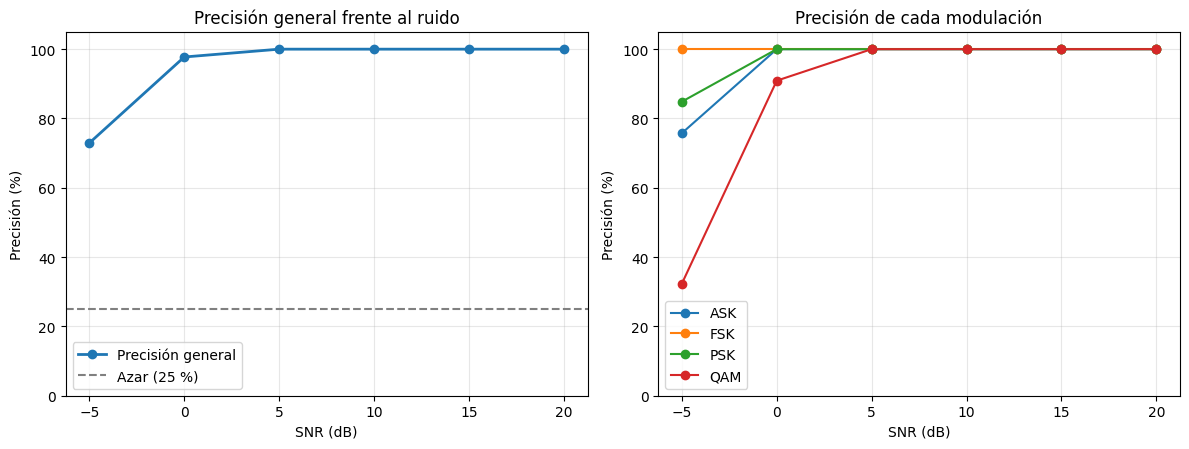

In [ ]:
filas_clase_snr = []
for clase_id, nombre in enumerate(modulaciones):
    for snr in sorted(np.unique(snr_test)):
        indices = (y_test == clase_id) & (snr_test == snr)
        n = int(indices.sum())
        if n:
            acc = 100 * np.mean(y_pred[indices] == y_test[indices])
            filas_clase_snr.append({"Modulación": nombre, "SNR (dB)": int(snr),
                                    "Señales": n, "Precisión (%)": round(acc, 2)})

por_clase_snr = pd.DataFrame(filas_clase_snr)
por_clase_snr.to_csv("precision_por_clase_y_snr.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(resultados_snr["SNR (dB)"], resultados_snr["Precisión (%)"],
             marker="o", linewidth=2, label="Precisión general")
axes[0].axhline(25, linestyle="--", color="gray", label="Azar (25 %)")
axes[0].set_title("Precisión general frente al ruido")
axes[0].set_xlabel("SNR (dB)")
axes[0].set_ylabel("Precisión (%)")
axes[0].set_ylim(0, 105)
axes[0].grid(alpha=0.3)
axes[0].legend()

for nombre in modulaciones:
    parte = por_clase_snr[por_clase_snr["Modulación"] == nombre]
    axes[1].plot(parte["SNR (dB)"], parte["Precisión (%)"], marker="o", label=nombre)
axes[1].set_title("Precisión de cada modulación")
axes[1].set_xlabel("SNR (dB)")
axes[1].set_ylabel("Precisión (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()
fig.savefig("rendimiento_snr_fase3.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
# Criterio orientativo: una precisión de 30 % o menos se considera
# cercana al 25 % esperado por azar. No es una prueba estadística.
cerca_del_azar = resultados_snr[resultados_snr["Precisión (%)"] <= 30]
if len(cerca_del_azar):
    print("En estos niveles el resultado quedó cerca del azar (≤ 30 %):")
    print(cerca_del_azar[["SNR (dB)", "Precisión (%)"]].to_string(index=False))
else:
    print("En los niveles medidos (−5 a 20 dB), la precisión general no cayó al 30 % o menos.")
    print("No se puede afirmar en qué SNR se 'vuelve ciego' sin probar niveles más bajos.")

En los niveles medidos (−5 a 20 dB), la precisión general no cayó al 30 % o menos.
No se puede afirmar en qué SNR se 'vuelve ciego' sin probar niveles más bajos.


## 3.4 Análisis de errores

Ahora revisaré cuál de las cuatro modulaciones tuvo **menos aciertos dentro de su propia clase**. Ese porcentaje también se conoce como *recall* de la clase.

Además mostraré los errores más repetidos entre parejas de modulaciones. La posible causa técnica se presentará como una **hipótesis**, porque la matriz muestra qué pasó, pero no demuestra por sí sola la causa.

In [ ]:
resumen_clases = []
for i, nombre in enumerate(modulaciones):
    total = int(matriz[i].sum())
    aciertos = int(matriz[i, i])
    resumen_clases.append({"Modulación": nombre, "Total": total,
                           "Aciertos": aciertos, "Errores": total - aciertos,
                           "Precisión dentro de clase (%)": round(100 * aciertos / total, 2)})

tabla_clases = pd.DataFrame(resumen_clases)
tabla_clases.to_csv("analisis_por_modulacion.csv", index=False)
print("ACIERTO POR MODULACIÓN")
print(tabla_clases.to_string(index=False))

menor = tabla_clases["Precisión dentro de clase (%)"].min()
dificiles = tabla_clases[tabla_clases["Precisión dentro de clase (%)"] == menor]["Modulación"].tolist()
print("\nModulación(es) más difícil(es):", ", ".join(dificiles), f"({menor:.2f}%)")

confusiones = []
for i in range(4):
    for j in range(4):
        if i != j and matriz[i, j] > 0:
            confusiones.append((int(matriz[i, j]), modulaciones[i], modulaciones[j]))
confusiones.sort(reverse=True)

print("\nConfusiones más frecuentes:")
if confusiones:
    for cantidad, real, predicha in confusiones[:3]:
        print(f"  {real} clasificada como {predicha}: {cantidad}")
else:
    print("  No hubo errores en estas señales de prueba.")

hipotesis = {
    "ASK": "Con ruido, los cambios de amplitud pueden quedar ocultos o parecerse a otras formas de onda.",
    "FSK": "El ruido puede dificultar la separación de las dos frecuencias utilizadas para representar bits.",
    "PSK": "Los cambios de fase pueden ser difíciles de distinguir cuando la forma de onda está alterada.",
    "QAM": "Al combinar varios niveles de amplitud y fase, sus símbolos pueden confundirse más fácilmente con ruido."
}
print("\nHipótesis técnica (no es una causa demostrada):")
for nombre in dificiles:
    print(f"{nombre}: {hipotesis[nombre]}")

ACIERTO POR MODULACIÓN
Modulación  Total  Aciertos  Errores  Precisión dentro de clase (%)
       ASK    200       192        8                           96.0
       FSK    200       200        0                          100.0
       PSK    200       195        5                           97.5
       QAM    200       174       26                           87.0

Modulación(es) más difícil(es): QAM (87.00%)

Confusiones más frecuentes:
  QAM clasificada como PSK: 25
  ASK clasificada como QAM: 7
  PSK clasificada como QAM: 5

Hipótesis técnica (no es una causa demostrada):
QAM: Al combinar varios niveles de amplitud y fase, sus símbolos pueden confundirse más fácilmente con ruido.


### Ejemplos de errores (si los hubo)

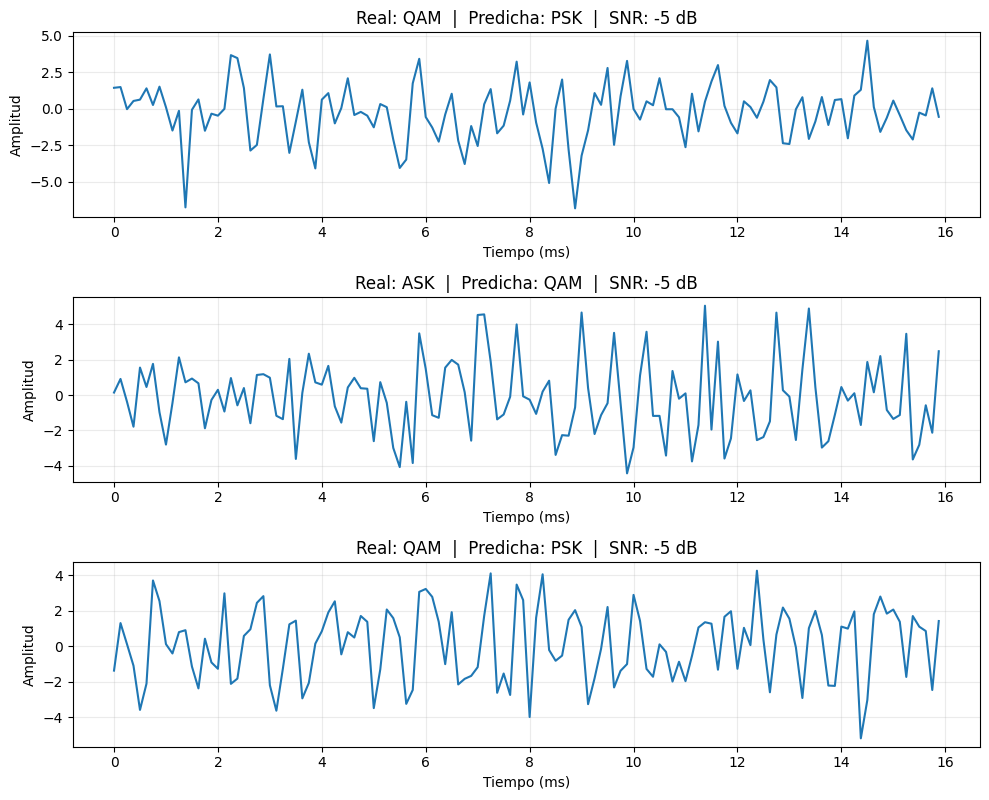

In [ ]:
indices_error = np.where(y_pred != y_test)[0]
if len(indices_error) == 0:
    print("No hubo predicciones incorrectas en este conjunto de prueba.")
else:
    mostrar = indices_error[:min(3, len(indices_error))]
    fig, axes = plt.subplots(len(mostrar), 1, figsize=(10, 2.7 * len(mostrar)))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, mostrar):
        t = np.arange(128) / 8000 * 1000
        ax.plot(t, X_test[i, :128])
        ax.set_title(f"Real: {modulaciones[y_test[i]]}  |  Predicha: {modulaciones[y_pred[i]]}  |  SNR: {snr_test[i]} dB")
        ax.set_xlabel("Tiempo (ms)")
        ax.set_ylabel("Amplitud")
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig("ejemplos_errores_fase3.png", dpi=150, bbox_inches="tight")
    plt.show()

## Conclusión y archivos para el reporte

In [ ]:
peor_snr = resultados_snr.loc[resultados_snr["Precisión (%)"].idxmin()]
resumen_texto = (
    "FASE 3 — EVALUACIÓN Y ROBUSTEZ\n"
    f"Precisión global en prueba: {exactitud*100:.2f}% (800 señales).\n"
    f"ASK confundidas con PSK: {ask_como_psk}; PSK confundidas con ASK: {psk_como_ask}.\n"
    f"Menor precisión por nivel SNR: {peor_snr['Precisión (%)']:.2f}% en {int(peor_snr['SNR (dB)'])} dB.\n"
    f"Modulación(es) con menor precisión: {', '.join(dificiles)} ({menor:.2f}%).\n"
    "La evaluación utiliza únicamente el conjunto de prueba reservado en Fase 2.\n"
)
print(resumen_texto)
with open("conclusiones_fase3.txt", "w", encoding="utf-8") as archivo:
    archivo.write(resumen_texto)

resultados = [
    "matriz_confusion_fase3.png", "matriz_confusion_fase3.csv",
    "precision_por_snr.csv", "precision_por_clase_y_snr.csv",
    "rendimiento_snr_fase3.png", "analisis_por_modulacion.csv",
    "conclusiones_fase3.txt"
]
if os.path.isfile("ejemplos_errores_fase3.png"):
    resultados.append("ejemplos_errores_fase3.png")
with zipfile.ZipFile("Resultados_Fase3.zip", "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    for nombre in resultados:
        zipf.write(nombre)
print("Archivo creado: Resultados_Fase3.zip")
print("Para descargarlo: haz clic en la carpeta de Colab (izquierda) y busca el ZIP.")

FASE 3 — EVALUACIÓN Y ROBUSTEZ
Precisión global en prueba: 95.12% (800 señales).
ASK confundidas con PSK: 1; PSK confundidas con ASK: 0.
Menor precisión por nivel SNR: 72.93% en -5 dB.
Modulación(es) con menor precisión: QAM (87.00%).
La evaluación utiliza únicamente el conjunto de prueba reservado en Fase 2.

Archivo creado: Resultados_Fase3.zip
Para descargarlo: haz clic en la carpeta de Colab (izquierda) y busca el ZIP.
